# PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (EDA)

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
PROC_DIR = os.path.join(ROOT, 'data', 'processed')
FIG_DIR = os.path.join(ROOT, 'reports', 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

In [3]:
df = pd.read_csv(os.path.join(PROC_DIR, 'train_clean.csv'))

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11426 entries, 0 to 11425
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   sentence         11426 non-null  str  
 1   sentiment        11426 non-null  int64
 2   topic            11426 non-null  int64
 3   sentiment_label  11426 non-null  str  
 4   topic_label      11426 non-null  str  
 5   sentence_clean   11426 non-null  str  
 6   word_count       11426 non-null  int64
 7   char_count       11426 non-null  int64
 8   is_no_content    11426 non-null  bool 
 9   sentence_seg     11426 non-null  str  
dtypes: bool(1), int64(4), str(5)
memory usage: 3.5 MB


In [5]:
df.head()

,sentence,sentiment,topic,sentiment_label,topic_label,sentence_clean,word_count,char_count,is_no_content,sentence_seg
0,slide giáo trình đầy đủ .,2,1,positive,training_program,slide giáo trình đầy đủ .,6,25,False,slide giáo_trình đầy đủ .
1,"nhiệt tình giảng dạy , gần gũi với sinh viên .",2,0,positive,lecturer,"nhiệt tình giảng dạy , gần gũi với sinh viên .",11,46,False,"nhiệt_tình giảng dạy , gần gũi với sinh_viên ."
2,đi học đầy đủ full điểm chuyên cần .,0,1,negative,training_program,đi học đầy đủ full điểm chuyên cần .,9,36,False,đi học đầy đủ full điểm chuyên cần .
3,chưa áp dụng công nghệ thông tin và các thiết ...,0,0,negative,lecturer,chưa áp dụng công nghệ thông tin và các thiết ...,18,76,False,chưa áp dụng công nghệ thông tin và các thiết ...
4,"thầy giảng bài hay , có nhiều bài tập ví dụ ng...",2,0,positive,lecturer,"thầy giảng bài hay , có nhiều bài tập ví dụ ng...",15,59,False,"thầy giảng bài hay , có nhiều bài_tập ví dụ ng..."


## 1. PHÂN BỐ NHÃN CẢM XÚC (SENTIMENT)

In [6]:
df['sentiment_label'].value_counts()

sentiment_label
positive    5643
negative    5325
neutral      458
Name: count, dtype: int64

In [7]:
df['sentiment_label'].value_counts(normalize=True) * 100

sentiment_label
positive    49.387362
negative    46.604236
neutral      4.008402
Name: proportion, dtype: float64

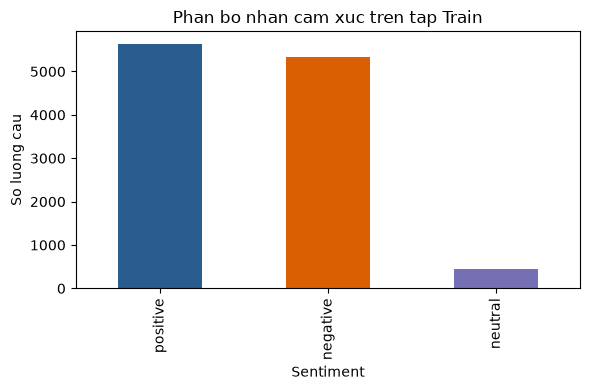

In [8]:
plt.figure(figsize=(6, 4))
df['sentiment_label'].value_counts().plot(kind='bar', color=['#2b5c8f', '#d95f02', '#7570b3'])
plt.title('Phan bo nhan cam xuc tren tap Train')
plt.xlabel('Sentiment')
plt.ylabel('So luong cau')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_sentiment_dist.png'), dpi=150)
plt.show()

## 2. PHÂN BỐ NHÃN CHỦ ĐỀ (TOPIC)

In [9]:
df['topic_label'].value_counts()

topic_label
lecturer            8166
training_program    2201
others               562
facility             497
Name: count, dtype: int64

In [10]:
df['topic_label'].value_counts(normalize=True) * 100

topic_label
lecturer            71.468580
training_program    19.263084
others               4.918607
facility             4.349729
Name: proportion, dtype: float64

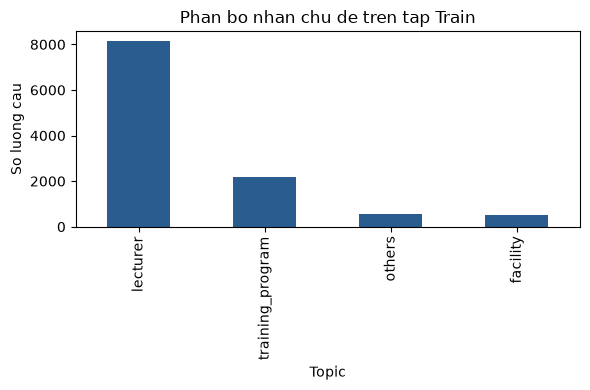

In [11]:
#Copy biểu đồ trên đổi sang cột topic_label
plt.figure(figsize=(6, 4))
df['topic_label'].value_counts().plot(kind='bar', color='#2b5c8f')
plt.title('Phan bo nhan chu de tren tap Train')
plt.xlabel('Topic')
plt.ylabel('So luong cau')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_topic_dist.png'), dpi=150)
plt.show()

## 3. THỐNG KÊ ĐỘ DÀI CÂU THEO NHÃN

In [12]:
df['word_count'].describe()

count    11426.000000
mean        14.324348
std         10.102416
min          2.000000
25%          8.000000
50%         11.000000
75%         17.000000
max        159.000000
Name: word_count, dtype: float64

In [13]:
df.groupby('sentiment_label')['word_count'].agg(['count', 'mean', 'median', 'std'])

,count,mean,median,std
sentiment_label,,,,
negative,5325,16.897653,13.0,12.077536
neutral,458,9.862445,7.0,8.392496
positive,5643,12.258196,10.0,7.154159


In [14]:
df.groupby('topic_label')['word_count'].agg(['count', 'mean', 'median', 'std'])

,count,mean,median,std
topic_label,,,,
facility,497,16.625755,13.0,11.283230
lecturer,8166,13.764144,11.0,9.247722
others,562,10.281139,8.0,9.288367
training_program,2201,16.915493,13.0,12.192440


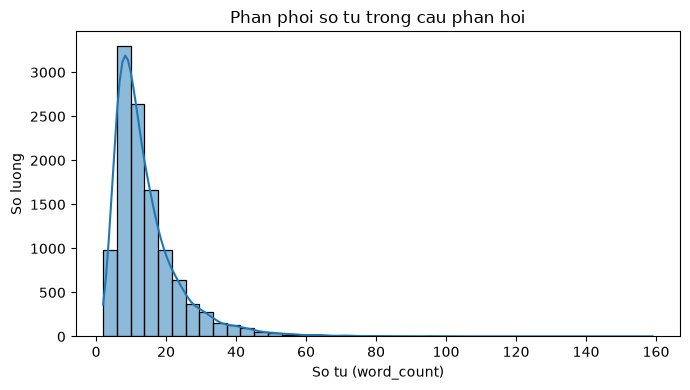

In [15]:
plt.figure(figsize=(7, 4))
sns.histplot(df['word_count'], bins=40, kde=True)
plt.title('Phan phoi so tu trong cau phan hoi')
plt.xlabel('So tu (word_count)')
plt.ylabel('So luong')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_word_count_hist.png'), dpi=150)
plt.show()

## 4. BẢNG CHÉO SENTIMENT X TOPIC

In [16]:
ct = pd.crosstab(df['topic_label'], df['sentiment_label'])
ct

sentiment_label,negative,neutral,positive
topic_label,,,
facility,474,10,13
lecturer,2909,186,5071
others,226,161,175
training_program,1716,101,384


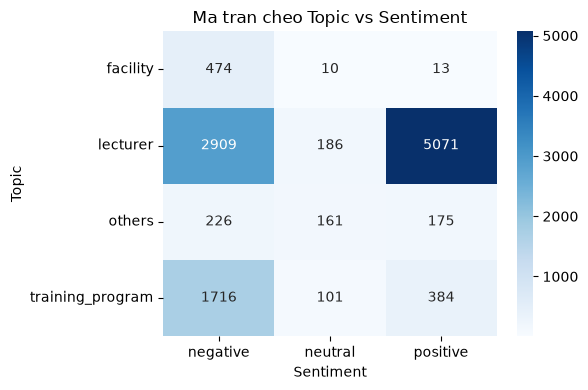

In [17]:
plt.figure(figsize=(6, 4))
sns.heatmap(ct, annot=True, fmt='d', cmap='Blues')
plt.title('Ma tran cheo Topic vs Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Topic')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_topic_sentiment_heatmap.png'), dpi=150)
plt.show()